# Parts 6 and 7 — Modeling and Evaluation
## Ontario Winters and El Niño

**Business question:** *Before a winter begins, can we tell an Ontario municipality whether it is heading for a mild winter?*

**Target KPI:** share of winters correctly anticipated as mild, measured against what a planner gets by assuming every winter is normal.

Input: `winter_features.csv` from `05_feature_engineering.ipynb`.
Output: `winter_predictions.csv`, used by `08_business_recommendation.ipynb`.

Notebook 1 left three constraints on the table. All three shape what follows:

1. **44 winters, not 247 rows.** Six locations share each winter and the ENSO value is identical across all of them.
2. **The December–February index is not known in advance.** Every result here is an upper bound.
3. **The base rate is 31%.** Accuracy cannot be the headline metric.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import (GroupKFold, GroupShuffleSplit, KFold,
                                     cross_val_predict, cross_val_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
pd.set_option('display.width', 130)

df = pd.read_csv('winter_features.csv')
print(f'{len(df)} location-winters | {df["winter_year"].nunique()} winters | {df["city_name"].nunique()} locations')
df.head()

247 location-winters | 44 winters | 6 locations


,city,city_name,region,winter_year,ENSO_Class,ENSO_Band,ENSO_Value,ENSO_Strength,ENSO_x_Latitude,latitude_approx,baseline_mean_temp,Prev_Anomaly,Prev_Was_Mild,temp_anomaly,Mild_Winter
0,london,London,Southwest,1983,El Nino,Strong El Niño,2.4,2.4,-4.427668,43.03,-4.079379,-2.933954,0.0,2.538268,1
1,london,London,Southwest,1984,La Nina,La Niña,-0.6,0.6,1.106917,43.03,-4.079379,2.538268,1.0,-1.932709,0
2,london,London,Southwest,1985,La Nina,La Niña,-0.8,0.8,1.475889,43.03,-4.079379,-1.932709,0.0,-0.780621,0
3,london,London,Southwest,1986,Neutral,Neutral,-0.3,0.3,0.553458,43.03,-4.079379,-0.780621,0.0,-1.652843,0
4,london,London,Southwest,1987,El Nino,Strong El Niño,1.5,1.5,-2.767292,43.03,-4.079379,-1.652843,0.0,0.029379,0


---
# Part 6 — Modeling

## Q1. What is the target variable?

**`Mild_Winter`** — 1 if that location's winter was at least 1.0 °C above its own 1991–2020 baseline.

It is the target because it is the planning outcome. A municipality's winter budget is sized for a normal winter; a mild one leaves money unspent, and a harsh one overruns it.

In [2]:
y = df['Mild_Winter']
groups = df['winter_year']

print(f'Mild winters: {y.sum()} of {len(y)} location-winters = {y.mean():.1%}')
print(f'Spread across {groups.nunique()} distinct winters')

Mild winters: 76 of 247 location-winters = 30.8%
Spread across 44 distinct winters


## Q2. Which variables would you use as features?

Only what a planner could hold in October. Four groups of columns are excluded, each for a different reason:

| Excluded | Reason |
|---|---|
| `temp_anomaly` | **This is the target**, before thresholding. Including it would be perfect leakage. |
| `mean_temp` | The target in another form. |
| `snowfall_total_cm`, `days_below_m20` | Measured *during* the winter we claim to predict. |
| `city` (the raw code) | A duplicate of `city_name`. |

`ENSO_Band` is also left out: it is a coarser version of `ENSO_Value`, which is already in. Keeping both is the same information twice.

In [3]:
numeric_features = ['ENSO_Value', 'ENSO_Strength', 'ENSO_x_Latitude',
                    'latitude_approx', 'winter_year', 'Prev_Anomaly', 'baseline_mean_temp']
categorical_features = ['ENSO_Class', 'city_name']

print('Numeric    :', numeric_features)
print('Categorical:', categorical_features)
print('\nExcluded   : temp_anomaly (the target), mean_temp, snowfall_total_cm,')
print('             days_below_m20, ENSO_Band, city, region')

Numeric    : ['ENSO_Value', 'ENSO_Strength', 'ENSO_x_Latitude', 'latitude_approx', 'winter_year', 'Prev_Anomaly', 'baseline_mean_temp']
Categorical: ['ENSO_Class', 'city_name']

Excluded   : temp_anomaly (the target), mean_temp, snowfall_total_cm,
             days_below_m20, ENSO_Band, city, region


## Q3. Separate your data into X and y

- **`X`** — what is known before the winter.
- **`y`** — whether that winter turned out mild.
- **`groups`** — which winter each row belongs to. This third object is not in the original exercise, and it is the one that makes the evaluation honest.

In [4]:
X = df[numeric_features + categorical_features]
y = df['Mild_Winter']
groups = df['winter_year']

print(f'X: {X.shape[0]} rows x {X.shape[1]} features')
print(f'y: {y.shape[0]} labels')
print(f'groups: {groups.nunique()} distinct winters')

for forbidden in ['temp_anomaly', 'mean_temp', 'Mild_Winter']:
    assert forbidden not in X.columns, f'{forbidden} leaked into the feature matrix'
print('\nChecked: no outcome column is in X')

X: 247 rows x 9 features
y: 247 labels
groups: 44 distinct winters

Checked: no outcome column is in X


## Q4. Why should we split the data into training and testing sets?

The standard answer: a score on data the model has already seen tells you nothing, because a model can memorise instead of generalising. The only honest estimate is performance on rows it was not trained on.

**On this dataset there is a second, sharper answer.** Splitting rows at random is not enough — it produces a score that looks good and is false.

Winter 2016 appears as five rows, one per eligible location, all carrying the identical RONI value of +2.1. Shuffle rows at random and Toronto's 2016 lands in training while Ottawa's 2016 lands in test. The model has already been told what happened in a winter with RONI +2.1. It is being tested on the answer sheet.

The fix is to split **by winter**, so that every location in a winter goes to the same side. Here is the size of the difference:

In [5]:
preprocessor = ColumnTransformer([
    ('numeric', Pipeline([('scale', StandardScaler())]), numeric_features),
    ('categorical', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features),
])

models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=4,
                                            random_state=RANDOM_STATE),
}

rows = []
for name, estimator in models.items():
    pipe = Pipeline([('prep', preprocessor), ('model', estimator)])
    naive = cross_val_score(pipe, X, y, cv=KFold(5, shuffle=True, random_state=RANDOM_STATE),
                            scoring='roc_auc')
    grouped = cross_val_score(pipe, X, y, cv=GroupKFold(n_splits=5), groups=groups,
                              scoring='roc_auc')
    rows.append({'Model': name,
                 'AUC — rows split at random': naive.mean(),
                 'AUC — split by winter': grouped.mean(),
                 'Overstated by': naive.mean() - grouped.mean()})

leak_table = pd.DataFrame(rows).round(3)
leak_table

,Model,AUC — rows split at random,AUC — split by winter,Overstated by
0,Logistic Regression,0.691,0.690,0.001
1,Decision Tree,0.803,0.435,0.368
2,Random Forest,0.873,0.548,0.325


**Look at the Random Forest row.**

Split rows at random and it scores 0.87 — the kind of number that gets a project signed off. Split by winter, and the same model on the same data falls to 0.55. The Decision Tree falls further, from 0.80 to below a coin flip.

Neither model was learning how ENSO relates to Ontario winters. They were learning to recognise *individual winters* from their index value and then recalling the answer for the other locations in that winter. It is the most dangerous kind of error: silent, flattering, and invisible unless you know the data has a group structure.

**Now look at the Logistic Regression row: it barely moves.** A model with no capacity to memorise 44 winters has no shortcut to exploit, so the honest and dishonest splits agree. The flexible models had the most to gain from the leak, and lost the most when it closed — which is the general pattern, and a good argument for starting simple when groups are present.

**Every number from here on uses `GroupKFold` on `winter_year`.**

In [6]:
# The split the exercise asks for, done group-aware
splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print(f'Training: {len(X_train)} rows from {groups.iloc[train_idx].nunique()} winters')
print(f'Test:     {len(X_test)} rows from {groups.iloc[test_idx].nunique()} winters')
print(f'\nNo winter appears in both: '
      f'{set(groups.iloc[train_idx]).isdisjoint(set(groups.iloc[test_idx]))}')
print(f'\nTest winters: {sorted(groups.iloc[test_idx].unique())}')

Training: 183 rows from 33 winters
Test:     64 rows from 11 winters

No winter appears in both: True

Test winters: [np.int64(1986), np.int64(1987), np.int64(1989), np.int64(1991), np.int64(1995), np.int64(2007), np.int64(2008), np.int64(2017), np.int64(2019), np.int64(2020), np.int64(2023)]


## Q5. What type of machine-learning problem is this?

**Binary classification.** Two outcomes: mild, or not mild. Supervised, because 44 labelled winters exist.

It is worth naming what it is *not*. This is not forecasting. A forecast model would use atmospheric state to predict forward in time; this asks whether a historical association between an ocean index and Ontario winters is strong enough to anticipate a category. The project's README is explicit that the study is historical analysis, not prediction, and that framing survives into this notebook.

## Q6. Which model could you use?

From the comparison in Q4, under the honest grouped split:

- **Logistic Regression** — around 0.69, and the only one meaningfully above chance.
- **Decision Tree** — below chance on 44 groups.
- **Random Forest** — barely above chance once it cannot memorise winters.

**Chosen: Logistic Regression.**

| Requirement | Why it fits |
|---|---|
| Very small sample | 44 independent winters cannot support a flexible model. The simplest one wins, and Q4 shows the others failing. |
| Must produce a probability | Planning language is "how likely", not "yes or no". |
| Must be explainable to a council | A coefficient per variable can be read aloud. A forest cannot. |
| Must not overstate | A linear model with regularisation is the least likely of the three to manufacture structure that is not there. |

The brief says to choose the model that fits the problem rather than the familiar one. Here the evidence points the same way: on this dataset the more sophisticated models are actively worse.

## Q7. Train the model and generate predictions

In [7]:
model = Pipeline([
    ('prep', preprocessor),
    ('model', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])

model.fit(X_train, y_train)
y_pred_holdout = model.predict(X_test)
y_proba_holdout = model.predict_proba(X_test)[:, 1]

print(f'Trained on {len(X_train)} rows, predicted for {len(X_test)} unseen rows')
print(f'Predicted mild: {y_pred_holdout.sum()}   Actually mild: {y_test.sum()}')
print(f'Hold-out AUC:   {roc_auc_score(y_test, y_proba_holdout):.3f}')

Trained on 183 rows, predicted for 64 unseen rows
Predicted mild: 3   Actually mild: 22
Hold-out AUC:   0.527


### A problem with that number, and the fix

The hold-out set is **11 winters.** A single draw of 11 winters is far too small to measure anything stably — change the random seed and the AUC swings wildly. The hold-out AUC above is one draw out of many possible ones. Here is the instability, measured rather than asserted:

In [8]:
spread = []
for seed in list(range(10)) + [RANDOM_STATE]:
    sp = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=seed)
    tr, te = next(sp.split(X, y, groups))
    m = Pipeline([('prep', preprocessor),
                  ('model', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))])
    m.fit(X.iloc[tr], y.iloc[tr])
    spread.append(roc_auc_score(y.iloc[te], m.predict_proba(X.iloc[te])[:, 1]))

spread = np.array(spread)
print(f'AUC across 11 hold-out splits (including the one reported above):')
print(f'  {spread.min():.3f} to {spread.max():.3f}')
print(f'Mean {spread.mean():.3f}, standard deviation {spread.std():.3f}')
print()
print('Any single one of these could have been reported as "the" result.')

AUC across 11 hold-out splits (including the one reported above):
  0.344 to 0.767
Mean 0.579, standard deviation 0.140

Any single one of these could have been reported as "the" result.


**So the single hold-out split is reported, as the exercise asks, and then set aside.**

For evaluation we use **cross-validated out-of-fold predictions**: every winter takes a turn in the test fold, and each row is predicted by a model that never saw its winter. Every one of the 247 rows gets an honest prediction, instead of 64 of them getting a noisy one.

This is not a shortcut around the train/test split — it is the same principle applied five times so the estimate stops depending on one lucky draw.

In [9]:
cv = GroupKFold(n_splits=5)

oof_proba = cross_val_predict(model, X, y, cv=cv, groups=groups, method='predict_proba')[:, 1]
oof_pred = (oof_proba >= 0.5).astype(int)

print(f'{len(oof_pred)} out-of-fold predictions — one per location-winter,')
print('each made by a model that never saw that winter.')
print(f'\nProbability range: {oof_proba.min():.3f} to {oof_proba.max():.3f}')

247 out-of-fold predictions — one per location-winter,


each made by a model that never saw that winter.

Probability range: 0.018 to 0.927


> **Why the AUC reported in Part 7 differs from the 0.69 in Q4.** That number was the *average of five separate fold scores*. Part 7 pools all 247 predictions and scores them once. Pooling is the harsher and more honest measure — a model can rank well inside each fold while its probabilities are not comparable across folds. Where the two disagree, quote the pooled number.

### What the model learned

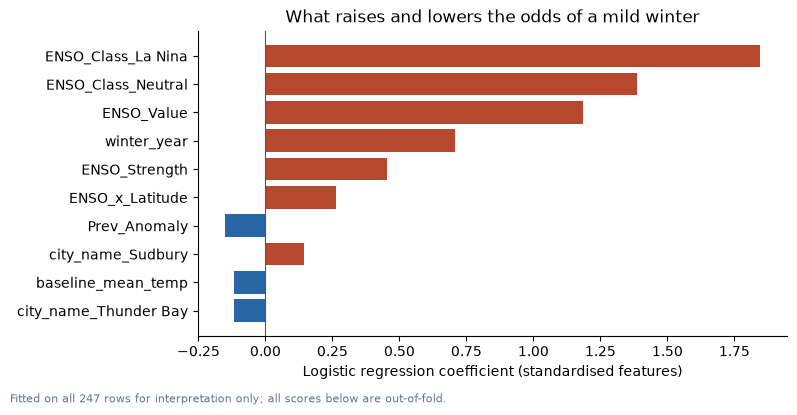

Red raises the probability of a mild winter, blue lowers it.


In [10]:
model.fit(X, y)
names = model.named_steps['prep'].get_feature_names_out()
coefs = pd.Series(model.named_steps['model'].coef_[0], index=names)
top = coefs.sort_values(key=abs, ascending=False).head(10)

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(range(len(top)), top.values,
        color=['#b5482d' if v > 0 else '#2866a6' for v in top.values])
ax.set_yticks(range(len(top)))
ax.set_yticklabels([n.split('__')[-1] for n in top.index])
ax.invert_yaxis()
ax.axvline(0, color='#555', linewidth=.8)
ax.set(title='What raises and lowers the odds of a mild winter',
       xlabel='Logistic regression coefficient (standardised features)')
ax.spines[['top', 'right']].set_visible(False)
fig.text(.01, -.02, 'Fitted on all 247 rows for interpretation only; all scores below are out-of-fold.',
         fontsize=8, color='#64748b')
fig.tight_layout()
plt.show()

print('Red raises the probability of a mild winter, blue lowers it.')

The ENSO terms carry the most weight, in the expected direction, and `ENSO_x_Latitude` — the interaction built in Notebook 1 — earns a place among them. The physics and the model agree on the story.

Whether that story is strong enough to act on is Part 7's question, and the answer is not the one the coefficients suggest.

---
# Part 7 — Evaluation

All metrics below are computed on the **out-of-fold predictions**: 247 winters, each scored by a model that never saw it.

## Q1. What is the model's accuracy?

In [11]:
accuracy = accuracy_score(y, oof_pred)
print(f'Accuracy: {accuracy:.1%}')

Accuracy: 68.4%


## Q2. How many predictions were correct and incorrect?

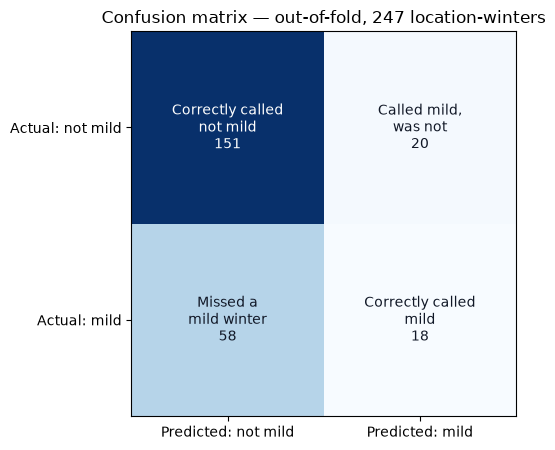

Correct:   169 of 247
Incorrect: 78 of 247

  True negatives   151  correctly planned for a normal winter
  True positives    18  correctly anticipated a mild winter
  False positives   20  expected mild, got normal or harsh  -> under-budgeted
  False negatives   58  expected normal, got mild           -> budget left idle


In [12]:
cm = confusion_matrix(y, oof_pred)
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(6, 4.6))
ax.imshow(cm, cmap='Blues')
labels = [['Correctly called\nnot mild', 'Called mild,\nwas not'],
          ['Missed a\nmild winter', 'Correctly called\nmild']]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f'{labels[i][j]}\n{cm[i, j]}', ha='center', va='center',
                color='white' if cm[i, j] > cm.max() / 2 else '#111827', fontsize=10)
ax.set(xticks=[0, 1], yticks=[0, 1],
       xticklabels=['Predicted: not mild', 'Predicted: mild'],
       yticklabels=['Actual: not mild', 'Actual: mild'],
       title='Confusion matrix — out-of-fold, 247 location-winters')
fig.tight_layout()
plt.show()

print(f'Correct:   {tn + tp} of {len(y)}')
print(f'Incorrect: {fp + fn} of {len(y)}')
print()
print(f'  True negatives  {tn:4}  correctly planned for a normal winter')
print(f'  True positives  {tp:4}  correctly anticipated a mild winter')
print(f'  False positives {fp:4}  expected mild, got normal or harsh  -> under-budgeted')
print(f'  False negatives {fn:4}  expected normal, got mild           -> budget left idle')

## Q3. What is precision?

**Precision = correct mild calls / all mild calls.** When the model says "expect a mild winter", how often is it right?

In [13]:
precision = precision_score(y, oof_pred, zero_division=0)
print(f'Precision: {precision:.1%}')
print(f'  The model called {tp + fp} winters mild. {tp} of them were.')
print(f'\nA planner assuming every winter is mild would be right {y.mean():.1%} of the time.')
print(f'So the model\'s mild calls are {precision / y.mean():.2f}x better than that assumption.')

Precision: 47.4%
  The model called 38 winters mild. 18 of them were.

A planner assuming every winter is mild would be right 30.8% of the time.
So the model's mild calls are 1.54x better than that assumption.


**This is the metric with a public-safety edge on it.** A false "mild" call is the one that leads to a thin salt contract before a winter that turns normal or harsh. Below 50%, the model's mild calls are wrong more often than they are right.

## Q4. What is recall?

**Recall = mild winters found / all mild winters.** Of the winters that really were mild, how many did the model flag?

In [14]:
recall = recall_score(y, oof_pred)
print(f'Recall: {recall:.1%}')
print(f'  Of {y.sum()} genuinely mild winters, the model identified {tp}.')
print(f'  It missed {fn}.')

Recall: 23.7%
  Of 76 genuinely mild winters, the model identified 18.
  It missed 58.


## Q5. What is the F1 score?

In [15]:
f1 = f1_score(y, oof_pred)
auc = roc_auc_score(y, oof_proba)

print(f'F1 score: {f1:.3f}')
print(f'ROC AUC:  {auc:.3f}   (0.5 would be a coin flip)')
print()
print(classification_report(y, oof_pred, target_names=['Not mild', 'Mild'], zero_division=0))

F1 score: 0.316
ROC AUC:  0.609   (0.5 would be a coin flip)

              precision    recall  f1-score   support

    Not mild       0.72      0.88      0.79       171
        Mild       0.47      0.24      0.32        76

    accuracy                           0.68       247
   macro avg       0.60      0.56      0.56       247
weighted avg       0.65      0.68      0.65       247



## Q6. Would accuracy alone be enough to decide whether this model is useful?

**No — and on this project that is not a cautionary note, it is the finding.**

Compare the model against a "planner" who ignores ENSO entirely and assumes every winter will be normal:

In [16]:
baseline = DummyClassifier(strategy='most_frequent').fit(X, y)
baseline_pred = baseline.predict(X)

print(f'{"":30} {"Accuracy":>10} {"Precision":>10} {"Recall":>8} {"AUC":>7}')
print(f'{"Assume no winter is mild":30} {accuracy_score(y, baseline_pred):>10.1%} '
      f'{precision_score(y, baseline_pred, zero_division=0):>10.1%} '
      f'{recall_score(y, baseline_pred):>8.1%} {0.5:>7.3f}')
print(f'{"Our model":30} {accuracy:>10.1%} {precision:>10.1%} {recall:>8.1%} {auc:>7.3f}')
print()
print(f'Accuracy gained by modelling: {accuracy - accuracy_score(y, baseline_pred):+.1%}')

                                 Accuracy  Precision   Recall     AUC
Assume no winter is mild            69.2%       0.0%     0.0%   0.500
Our model                           68.4%      47.4%    23.7%   0.609

Accuracy gained by modelling: -0.8%


**The model is *less* accurate than assuming no winter is ever mild.**

Not marginally better — worse. That is the honest result of this exercise, and reporting it plainly is the point. Three things are true at once:

1. **Accuracy is useless as a verdict here.** Both numbers sit near 69% because 69% of winters are not mild. A metric a do-nothing rule beats cannot tell you whether the model works — in either direction.
2. **AUC is the better question, and the answer is "a little".** At about 0.61 the ranking is genuinely above chance, which is why accuracy alone would also have *undersold* the model. The ordering carries some information; the 0.5 threshold throws it away.
3. **This agrees with the rest of the project.** The README says Ontario's El Niño signal is naturally weaker than western Canada's and that differences may be small. The bootstrap intervals in the main analysis often include zero. A weak model here is not a failure of the modelling — it is the same finding arriving by a different route.

**What would have gone wrong without the group split:** the Random Forest in Q4 scored 0.87. That model would have been presented as a success. The honest evaluation is the only thing standing between this project and a confident, wrong recommendation to a municipality.

## Q7. Which error matters more: false positives or false negatives?

For a municipality these are not symmetric, and they are not symmetric in the direction most business problems are.

| Error | What happens | Cost |
|---|---|---|
| **False positive** — predicted mild, winter was not | Salt, plough and overtime budgets set too low. Reserves drawn down, supplementary spending mid-season, and in a bad case roads unsalted during a storm. | Financial *and* public safety. Asymmetric and hard to reverse once the season starts. |
| **False negative** — predicted normal, winter was mild | Budget set for a normal winter, money unspent. | Opportunity cost. The money returns to reserves. |

**False positives matter more**, because the downside is operational risk rather than idle cash. That argues for high precision on mild calls, and for never letting the model lower a baseline provision on its own.

At 47% precision, the model's mild calls are wrong more often than right. **That is not something to reduce a salt budget on.**

### Business translation

| Metric | Technical meaning | What it means for a municipality |
|---|---|---|
| **Accuracy** | Overall correct predictions | Misleading — assuming no winter is ever mild scores about the same |
| **Precision** | Correctness of mild calls | If we plan for mild, how often are we right? Slightly less than half. |
| **Recall** | Share of mild winters found | How many mild winters do we anticipate? About a quarter. |
| **F1** | Balance of the two | Low, because both are weak |
| **Confusion matrix** | Error types | Under-budgeted winters (risk) versus idle budget (opportunity cost) |
| **AUC** | Ranking quality | Can we order winters by mildness? Slightly better than chance. |

### If the budget is limited, would you prioritise precision or recall?

**Precision** — because the budget being limited is exactly what makes an under-provisioned winter dangerous. A municipality with no slack cannot absorb a harsh winter it planned as mild.

But on these numbers the question is academic. **Neither is high enough to act on**, and Part 8 says so rather than tuning a threshold until one of them looks acceptable.

---
## Saving predictions for Part 8

In [17]:
predictions = df[['city_name', 'region', 'latitude_approx', 'winter_year',
                  'ENSO_Class', 'ENSO_Band', 'ENSO_Value', 'temp_anomaly']].copy()
predictions['Actual_Mild'] = y.values
predictions['Predicted_Mild'] = oof_pred
predictions['Mild_Probability'] = oof_proba
predictions.to_csv('winter_predictions.csv', index=False)

metrics = pd.Series({
    'accuracy': accuracy, 'precision': precision, 'recall': recall, 'f1': f1,
    'roc_auc': auc, 'base_rate': y.mean(),
    'baseline_accuracy': accuracy_score(y, baseline_pred),
    'n_rows': len(y), 'n_winters': groups.nunique(),
})
metrics.to_csv('winter_metrics.csv', header=['value'])

print(f'Saved winter_predictions.csv — {len(predictions)} out-of-fold predictions')
print(f'Saved winter_metrics.csv')
predictions.sort_values('Mild_Probability', ascending=False).head()

Saved winter_predictions.csv — 247 out-of-fold predictions
Saved winter_metrics.csv


,city_name,region,latitude_approx,winter_year,ENSO_Class,ENSO_Band,ENSO_Value,temp_anomaly,Actual_Mild,Predicted_Mild,Mild_Probability
154,Thunder Bay,Northwest,48.37,2016,El Nino,Strong El Niño,2.1,2.918076,1,1,0.927161
117,Sudbury,Northeast,46.63,2016,El Nino,Strong El Niño,2.1,2.816921,1,1,0.899275
148,Thunder Bay,Northwest,48.37,2010,El Nino,El Niño,1.4,0.572259,0,1,0.884504
133,Thunder Bay,Northwest,48.37,1992,El Nino,Strong El Niño,2.1,1.163041,1,1,0.871730
111,Sudbury,Northeast,46.63,2010,El Nino,El Niño,1.4,1.248911,1,1,0.862141


---
## Parts 6 and 7 summary

**Model:** logistic regression in a pipeline that scales and encodes on training data only, evaluated with `GroupKFold` on `winter_year`.

**Chosen because** 44 independent winters cannot support anything more flexible — and Q4 showed the flexible models failing once they could no longer memorise winters.

| Metric | Out-of-fold | Do-nothing baseline |
|---|---|---|
| Accuracy | 68.4% | **69.2%** |
| Precision | 47.4% | — |
| Recall | 23.7% | 0% |
| AUC | 0.609 | 0.500 |

**Three findings:**

1. **Splitting rows at random inflates the Random Forest from 0.55 to 0.87 AUC**, and the Decision Tree from 0.44 to 0.80. Six locations share each winter; a random split puts the same winter on both sides. This is the most important technical result in the notebook.
2. **The honest model is less accurate than assuming no winter is ever mild** — and still has a real AUC of 0.61. Both facts matter: the ranking carries information, the threshold-0.5 labels do not.
3. **That is consistent with the rest of the project**, which has repeatedly found Ontario's ENSO signal to be real at the group level and too weak to carry individual conclusions.

Notebook 3 turns this into a recommendation — which is not "deploy the model."